In [1]:
import sys
from pathlib import Path
import pandas as pd
import joblib

sys.path.insert(0, str(Path("../").resolve()))

from src.explainability import (
    get_permutation_importance,
    top_features
)

In [2]:
train = pd.read_csv("../data/processed/train_processed.csv")
test = pd.read_csv("../data/processed/test_processed.csv")

X_train = train.drop("is_fraud", axis=1)
y_train = train["is_fraud"]

X_test = test.drop("is_fraud", axis=1)
y_test = test["is_fraud"]

feature_names = X_train.columns.tolist()

print("Features:", feature_names)

Features: ['amt', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long', 'unix_time', 'hour', 'day_of_week', 'month', 'age', 'merchant_frequency', 'customer_frequency', 'category_frequency', 'category_encoded']


In [3]:
fraud_model = joblib.load("../models/fraud_model.pkl")

print(type(fraud_model).__name__)

GradientBoostingClassifier


In [4]:
importance = get_permutation_importance(
    fraud_model,
    X_test,
    y_test,
    feature_names
)

importance

,feature,importance
0,amt,0.723152
1,category_frequency,0.658405
2,hour,0.207684
3,customer_frequency,0.043365
4,age,0.028231
5,category_encoded,0.002830
6,lat,0.000000
7,long,0.000000
8,unix_time,0.000000
9,merch_long,0.000000


In [5]:
importance.head(10)

,feature,importance
0,amt,0.723152
1,category_frequency,0.658405
2,hour,0.207684
3,customer_frequency,0.043365
4,age,0.028231
5,category_encoded,0.002830
6,lat,0.000000
7,long,0.000000
8,unix_time,0.000000
9,merch_long,0.000000


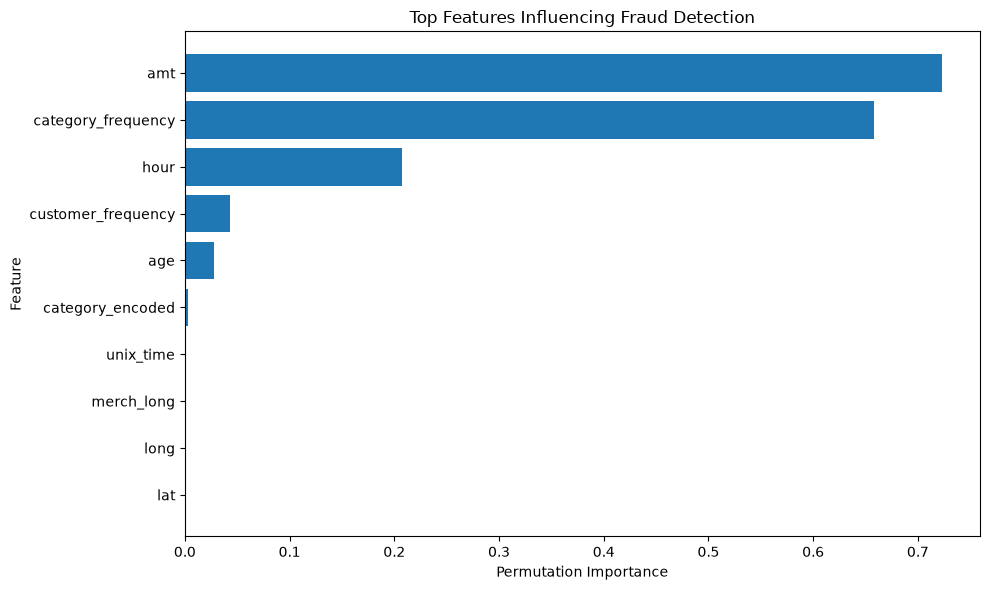

In [6]:
import matplotlib.pyplot as plt

top_importance = importance.head(10).sort_values(
    "importance"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_importance["feature"],
    top_importance["importance"]
)
plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Top Features Influencing Fraud Detection")
plt.tight_layout()
plt.show()

In [7]:
importance.to_csv(
    "../reports/feature_importance.csv",
    index=False
)

In [8]:
top = top_features(
    fraud_model,
    X_test,
    y_test,
    feature_names,
    n=5
)

top

,feature,importance
0,amt,0.723152
1,category_frequency,0.658405
2,hour,0.207684
3,customer_frequency,0.043365
4,age,0.028231


In [9]:
print("Explainability analysis completed")
print("Feature importance saved to reports/feature_importance.csv")
print("\nTop features:")
print(top)

Explainability analysis completed
Feature importance saved to reports/feature_importance.csv

Top features:
              feature  importance
0                 amt    0.723152
1  category_frequency    0.658405
2                hour    0.207684
3  customer_frequency    0.043365
4                 age    0.028231
